# 02 · Texto: EmbeddingGemma frente a los baselines

La primera pregunta del proyecto: **¿qué tan bien queda representado un video a partir de su texto?** Comparamos tres formas de convertir el mismo texto (título + tags + descripción) en un vector:

| modelo | qué hace | dimensiones |
|---|---|---|
| **TF-IDF + SVD** | cuenta palabras, da más peso a las raras y comprime | 768 |
| **MiniLM** | red pequeña de sentence-transformers, entrenada en inglés | 384 |
| **EmbeddingGemma 2** | modelo de Google, multilingüe, lee la frase completa | 768 |

TF-IDF solo ve palabras idénticas: para él, "fútbol" y "soccer" no tienen nada en común. Los modelos neuronales deberían acercarlos. Queremos medir cuánto se nota.

> Los vectores, las proyecciones UMAP y las métricas ya están calculados. Si cambian los datos, se regeneran con `python3 -m analysis.metricas` (~5 min).

In [1]:
import sys
from pathlib import Path

# Los notebooks viven en notebooks/, pero los datos (data/) y el código (analysis/, recolect/)
# están en la raíz del repo. Así funcionan abriéndolos desde cualquiera de las dos carpetas.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
# True para sobrescribir las figuras que usa el informe (informe/figs/)
GUARDAR_FIGS = False
FIGS = ROOT / "informe" / "figs"

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

from analysis.metricas import DATA, cargar_videos, matriz
from analysis.graficos import INK, MUTED, GRID, estilo, corto, plot3d, lollipop

estilo()

In [3]:
df = cargar_videos()                                      # videos con todas las representaciones + su categoría
metricas = pd.read_csv(DATA / "metricas.csv", index_col="modelo")
proy = pd.read_parquet(DATA / "proyecciones.parquet")     # UMAP 3D de cada representación
assert (proy["pid"] == df["pid"]).all()                   # mismas filas y mismo orden

TEXTO = {"tfidf": "TF-IDF", "minilm": "MiniLM", "text": "Gemma · texto"}
X = {rep: matriz(df, rep) for rep in TEXTO}
{TEXTO[rep]: M.shape for rep, M in X.items()}

{'TF-IDF': (34771, 768), 'MiniLM': (34771, 384), 'Gemma · texto': (34771, 768)}

## 1. Un ejemplo antes de los números

Elegimos un video y buscamos sus 5 vecinos más cercanos con cada modelo. Como todos los vectores están normalizados (largo 1), **la similitud coseno es solo un producto punto**: `X @ X[i]`.

In [4]:
def vecinos(i, n=5):
    print(f"CONSULTA: {df.title[i]}   [{df.vertical[i]}]\n")
    for rep, nombre in TEXTO.items():
        sims = X[rep] @ X[rep][i]
        print(f"— {nombre}")
        for j in np.argsort(-sims)[1:n + 1]:      # el primero es el mismo video
            print(f"   {sims[j]:.2f}  {corto(df.title[j], 70):<72} [{df.vertical[j]}]")
        print()

# busca un video por una palabra del título (prueba con otras: "receta", "minecraft", "piano"...)
i = df.index[df.title.str.contains("guitar", case=False)][0]
vecinos(i)

CONSULTA: Kyuss - Writhe on guitar   [Arts & Entertainment]

— TF-IDF
   0.42  Everybody Hurts (R.E.M.) Guitar/Vocal Cover                              [Arts & Entertainment]
   0.41  Fight Inside | RED | Guitar Cover | HD!                                  [Arts & Entertainment]
   0.40  AND THEN THE BASTARD JUMPED OVERBOARD                                    [Arts & Entertainment]
   0.40  ♥ Polymer Clay Nerdy Glasses Tutorial ♥                                  [Science]
   0.39  Kinky Curly Knot Today, Kinky Curly Curling Custard                      [Beauty & Fitness]

— MiniLM
   0.69  Dżem-Skazany na Bluesa                                                   [Arts & Entertainment]
   0.66  Бля (Ничего не успел)                                                    [Arts & Entertainment]
   0.65  The Joker drum Cover w/ Lyrics                                           [Arts & Entertainment]
   0.64  K-on!　「ふわふわ時間」 ギターカバー                                                    [Arts & Enterta

Fíjate en dos cosas: si los vecinos comparten la categoría de la consulta, y si los modelos neuronales encuentran videos relacionados **aunque no repitan las mismas palabras** (otro idioma, sinónimos, el mismo tema dicho de otra forma).

## 2. ¿Por qué UMAP y no PCA para el mapa?

Los vectores tienen 768 dimensiones y el mapa de la web es 3D. Lo más simple sería PCA, pero si la información está repartida en muchas direcciones, 3 componentes se quedan con muy poco. Veamos cuánta varianza explica cada componente de EmbeddingGemma:

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


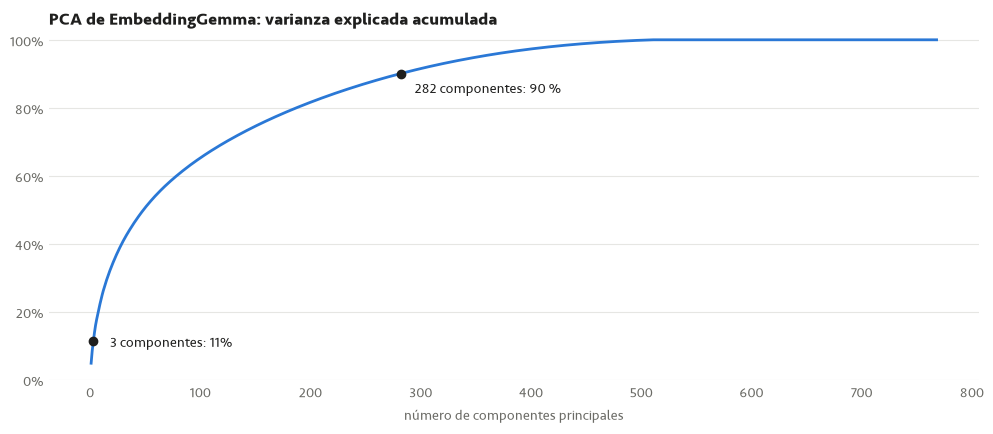

3 componentes explican solo el 11.2% de la varianza


In [5]:
pca = PCA().fit(X["text"])
acumulada = np.cumsum(pca.explained_variance_ratio_)
k90 = np.argmax(acumulada >= 0.9) + 1

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(range(1, len(acumulada) + 1), acumulada, color="#2a78d6", lw=2)
ax.scatter([3, k90], acumulada[[2, k90 - 1]], color=INK, zorder=3)
ax.annotate(f"3 componentes: {acumulada[2]:.0%}", (3, acumulada[2]), xytext=(12, -4), textcoords="offset points", color=INK)
ax.annotate(f"{k90} componentes: 90 %", (k90, acumulada[k90 - 1]), xytext=(10, -14), textcoords="offset points", color=INK)
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("número de componentes principales", color=MUTED)
ax.set_title("PCA de EmbeddingGemma: varianza explicada acumulada", loc="left", fontweight="bold", color=INK)
ax.grid(axis="y", color=GRID)
ax.tick_params(colors=MUTED, length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
plt.show()

print(f"3 componentes explican solo el {acumulada[2]:.1%} de la varianza")

Con 3 componentes, PCA tira casi toda la información. UMAP no intenta conservar la varianza sino **los vecinos**: que lo que estaba cerca en 768-d siga cerca en 3-d, que es justo lo que necesita un mapa para explorar.

Comparamos cuatro opciones, todas con EmbeddingGemma (`data/metricas_proyecciones.csv`):

- **Trustworthiness:** de los vecinos que aparecen en 3D, qué fracción eran también vecinos en el espacio original (1 = perfecto).
- **Silhouette:** si las categorías quedan como grupos separados (-1 a 1; cerca de 0 = mezcladas).
- **kNN** y **NMI:** las mismas del notebook, aplicadas a cada proyección.

Las métricas que comparan todos los pares (trustworthiness y silhouette) usan 5.000 videos al azar.

In [6]:
proyecciones = pd.read_csv(DATA / "metricas_proyecciones.csv", index_col="proyeccion")
proyecciones

,trustworthiness,silhouette,knn_acc,NMI_kmeans
proyeccion,,,,
PCA 3D,0.828,-0.133,0.643,0.325
UMAP 3D,0.956,-0.099,0.771,0.378
PCA 282 + UMAP 3D,0.958,-0.101,0.773,0.364
Original (768 dims),NaN,-0.003,0.798,0.351
Baseline mayoría,NaN,NaN,0.347,NaN


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


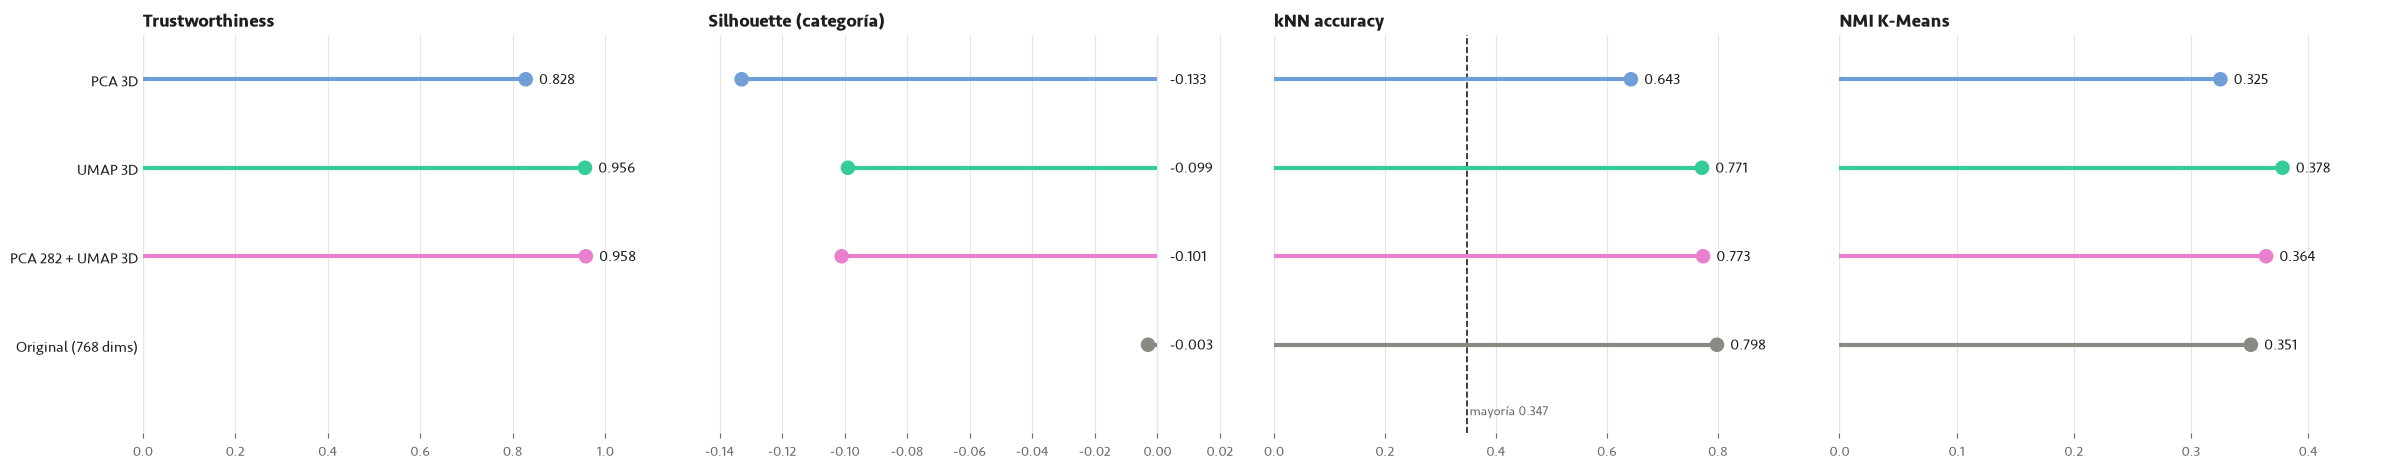

In [7]:
COLORES_PROY = {nombre: color for nombre, color in zip(proyecciones.index, ["#709ed7", "#34cd97", "#e980cf", "#8a8a85"])}
fig = lollipop(proyecciones,
               [("trustworthiness", "Trustworthiness"), ("silhouette", "Silhouette (categoría)"),
                ("knn_acc", "kNN accuracy"), ("NMI_kmeans", "NMI K-Means")],
               modelos=[n for n in proyecciones.index if n != "Baseline mayoría"], colores=COLORES_PROY)
if GUARDAR_FIGS:
    fig.savefig(FIGS / "metricas_text.png", dpi=200, bbox_inches="tight")
plt.show()

La silhouette sale cerca de 0 o negativa en todas: los vecindarios tienen sentido (kNN alto), pero las categorías gruesas no forman islas separadas. Es esperable con 25 categorías amplias que se solapan (un video de un juego de carreras es *Games* y también *Autos & Vehicles*).

## 3. Las métricas

Para cada modelo calculamos tres cosas (en `analysis/metricas.py`):

- **kNN accuracy (espacio original):** tomamos los 15 vecinos de cada video y votamos su categoría. Si acierta seguido, los vecinos tienen sentido.
- **kNN accuracy (UMAP 3D):** lo mismo, pero en el mapa 3D. Mide cuánto se pierde al proyectar.
- **NMI de K-Means (UMAP 3D):** agrupamos el mapa en tantos grupos como categorías y medimos cuánto se parecen esos grupos a las categorías reales (0 = nada, 1 = idénticos).

La línea punteada es el baseline de mayoría.

In [8]:
metricas

,knn_acc_original,knn_acc_umap,NMI_kmeans_umap,trustworthiness
modelo,,,,
TF-IDF,0.609,0.560,0.134,0.863
MiniLM,0.698,0.675,0.297,0.888
Gemma · texto,0.798,0.771,0.378,0.956
Gemma · imagen,0.784,0.769,0.391,0.929
Gemma · imagen + texto,0.819,0.791,0.364,0.958
Gemma · fusión tardía,0.838,0.823,0.452,0.955
Baseline mayoría,0.347,NaN,NaN,NaN


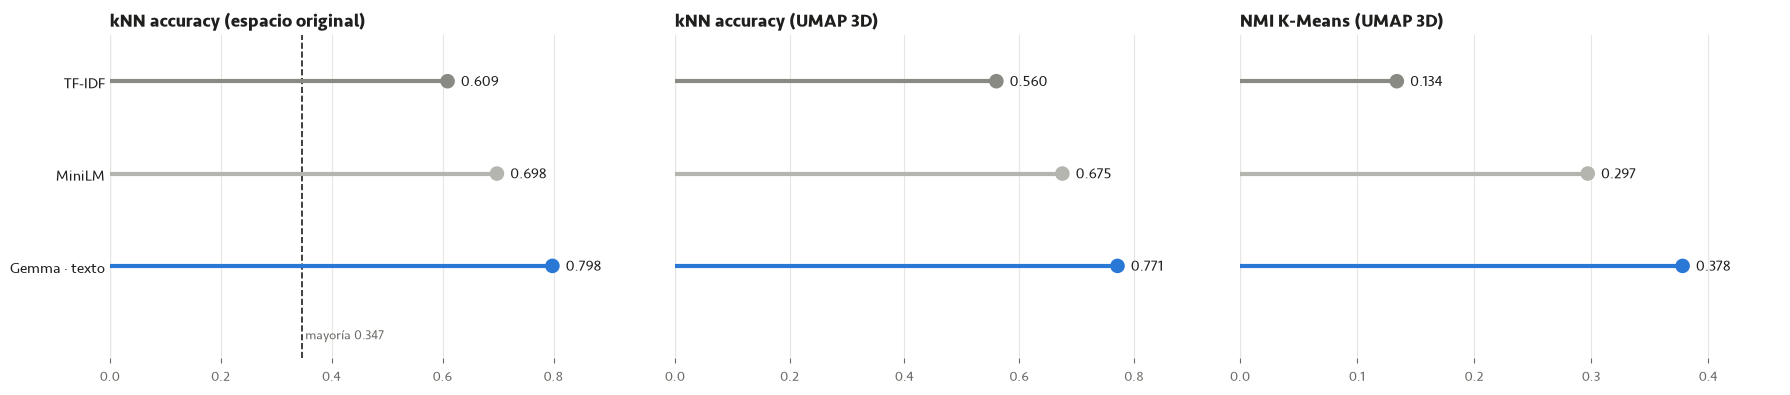

In [9]:
fig = lollipop(metricas,
               [("knn_acc_original", "kNN accuracy (espacio original)"),
                ("knn_acc_umap", "kNN accuracy (UMAP 3D)"),
                ("NMI_kmeans_umap", "NMI K-Means (UMAP 3D)")],
               modelos=list(TEXTO.values()))
if GUARDAR_FIGS:
    fig.savefig(FIGS / "metricas_modelos.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Los mapas

El mismo UMAP aplicado a cada modelo, coloreado por categoría. Se puede girar, hacer zoom y pasar el mouse por los puntos para ver los títulos. En un buen mapa las categorías forman regiones; en uno malo se ve una nube mezclada.

Con ~35 mil puntos los gráficos pesan. Si van lentos, usa una muestra: `plot3d(proy.sample(10_000, random_state=0), ...)`.

In [10]:
plot3d(proy, "tfidf", "UMAP 3D · TF-IDF")

In [11]:
plot3d(proy, "minilm", "UMAP 3D · MiniLM")

In [12]:
plot3d(proy, "text", "UMAP 3D · EmbeddingGemma (texto)")

### en conclusión

- EmbeddingGemma supera a MiniLM y a TF-IDF en las tres métricas, y los tres quedan muy por encima del baseline de mayoría.
- Pasar de 768-d al mapa 3D cuesta poco (compara la primera y la segunda columna): UMAP conserva bien los vecinos, mucho mejor que PCA.
- Los modelos neuronales no necesitan que se repitan las palabras exactas, y eso se nota en los vecinos.
- Por eso el mapa de la web usa EmbeddingGemma: es el mismo modelo que después nos deja sumar las miniaturas (notebook 03).